# Import

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats
from scipy.stats import f_oneway
import statsmodels.api as sm
from statsmodels.formula.api import ols


from analysis.analyzer import TTTH_Analyzer as Analyzer

pd.set_option('display.max_columns', None)

# Get data

In [2]:
# Trước đó có chạy câu lệnh -> để unzip và lấy nhãn

# cd lycos-ids2017       
# for zip_file in pcap_lycos/*.zip; do unzip -n "$zip_file" -d pcap_lycos; done
# python3 labelling.py

In [3]:
# folder_order = "01_raw_data"

# file_list = sorted(
#     os.path.join(folder_order, file)
#     for file in os.listdir(folder_order)
#     if file.endswith('.csv')
# )

# df_list = []
# for file in file_list:
#     df_day = pd.read_csv(file)
#     df_day['source_day'] = os.path.basename(file).split('-')[0]
#     df_list.append(df_day)

# df_raw = pd.concat(df_list, ignore_index=True)
# del df_list, df_day
# columns_raw = [col for col in df_raw.columns if col != 'source_day']

# df_raw.to_csv("02_merge_data/data_raw.csv", index=False)

# df_raw.head()

In [9]:
# Đọc từ file đã merge
df_raw = pd.read_csv("02_merge_data/data_raw.csv")

# Chỉ dự báo xem có bị tấn công hay không
df_raw["is_attack"] = np.where(
    df_raw["label"].str.lower().eq("benign"),
    "safe",
    "attack"
)
df_raw["is_attack"] = df_raw["is_attack"].eq("attack").astype("int8")

print(df_raw["is_attack"].value_counts())

df_raw

df_raw

is_attack
0    1395675
1     441823
Name: count, dtype: int64


,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,label,source_day,is_attack
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.3,3268,192.168.10.50,56108,6,1499428790315195,112740690,2.000,403.0,0.0,158.333333,31450.099291,177.341758,6.741133e+01,0.425756,0.141919,0.283837,16,1152,72.0,0.0,72.000,0.000000,512,32,16,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16399772.0,3.0,2.398738e+06,5.798698e+06,112740348,16400110.0,3.0,7.516023e+06,8.323385e+06,112740690,16399772.0,3.0,3.636796e+06,6.848761e+06,380.0,343.0,3.594286e+02,1.199802e+01,16399772.0,15375229.0,1.610540e+07,4.988048e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,144.000000,2.000000,806.000000,4.000000,2078,377,benign,Friday,0
1,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,1499428790316273,112740560,0.500,403.0,0.0,239.666667,30619.460993,174.984174,1.020396e+02,0.425756,0.283838,0.141919,32,6448,403.0,0.0,201.500,204.724205,1024,32,16,16,5056,316.0,0.0,316.0,0.000000,512,32,16,16399782.0,2.0,2.398735e+06,5.798710e+06,112740560,16399782.0,2.0,3.636792e+06,6.848777e+06,112740242,16400110.0,4.0,7.516016e+06,8.323376e+06,330.0,285.0,3.202857e+02,1.574499e+01,16399782.0,15375263.0,1.610543e+07,4.987937e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,806.000000,4.000000,632.000000,2.000000,955,2078,benign,Friday,0
2,192.168.10.9-224.0.0.22-0-0-2,192.168.10.9,0,224.0.0.22,0,2,1499428834843793,54760,0.000,8.0,8.0,8.000000,0.000000,0.000000,5.843682e+02,73.046019,73.046019,0.000000,4,32,8.0,8.0,8.000,0.000000,32,8,4,0,0,0.0,0.0,0.0,0.000000,0,0,0,53431.0,108.0,1.825333e+04,3.046984e+04,54760,53431.0,108.0,1.825333e+04,3.046984e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,32.0,4.0,5.843682e+02,0.0,0.0,0.0,32.000000,4.000000,0.000000,0.000000,-1,-1,benign,Friday,0
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,1499428834845380,100126,0.000,28.0,28.0,28.000000,0.000000,0.000000,6.152248e+03,219.723149,219.723149,0.000000,22,616,28.0,28.0,28.000,0.000000,176,8,22,0,0,0.0,0.0,0.0,0.000000,0,0,0,100055.0,1.0,4.767905e+03,2.183302e+04,100126,100055.0,1.0,4.767905e+03,2.183302e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,616.0,22.0,6.152248e+03,0.0,0.0,0.0,616.000000,22.000000,0.000000,0.000000,-1,-1,benign,Friday,0
4,192.168.10.9-192.168.10.3-137-137-17,192.168.10.9,137,192.168.10.3,137,17,1499428835164943,93069427,1.000,68.0,50.0,59.000000,46.153846,6.793662,2.535741e+01,0.429787,0.214893,0.214893,20,1180,68.0,50.0,59.000,9.233805,160,8,20,20,1180,62.0,0.0,59.0,3.077935,160,8,20,50763066.0,3.0,2.386396e+06,9.205496e+06,93069292,50763154.0,3.0,4.898384e+06,1.288064e+07,93069201,50763201.0,3.0,4.898379e+06,1.288065e+07,11894792.0,1512212.0,6.703502e+06,7.3

In [10]:
# rename_map = {
#     'flow_id': 'Mã luồng',
#     'src_addr': 'IP nguồn',
#     'src_port': 'Cổng nguồn',
#     'dst_addr': 'IP đích',
#     'dst_port': 'Cổng đích',
#     'ip_prot': 'Giao thức IP',
#     'timestamp': 'Thời điểm bắt đầu',
#     'flow_duration': 'Thời lượng luồng (µs)',
#     'down_up_ratio': 'Tỷ lệ chiều xuống / chiều lên',
#     'bytes_per_s': 'Byte mỗi giây',
#     'pkt_per_s': 'Gói mỗi giây',
#     'fwd_pkt_per_s': 'Gói mỗi giây chiều đi',
#     'bwd_pkt_per_s': 'Gói mỗi giây chiều về',
#     'fwd_pkt_cnt': 'Số gói chiều đi',
#     'bwd_pkt_cnt': 'Số gói chiều về',
#     'fwd_non_empty_pkt_cnt': 'Số gói có dữ liệu chiều đi',
#     'bwd_non_empty_pkt_cnt': 'Số gói có dữ liệu chiều về',
#     'fwd_tcp_init_win_bytes': 'Cửa sổ TCP ban đầu chiều đi',
#     'bwd_tcp_init_win_bytes': 'Cửa sổ TCP ban đầu chiều về',
#     'label': 'Nhãn phân lớp',
#     'source_day': 'Ngày nguồn dữ liệu',
#     "is_attack": "Có tấn công"
# }

# for flag in ['SYN', 'fin', 'rst', 'ack', 'psh', 'urg', 'cwr', 'ece']:
#     rename_map[f'flag_{flag}'] = f'Số cờ {flag.upper()}'

# for direction, ten in [('fwd', 'chiều đi'), ('bwd', 'chiều về')]:
#     for flag in ['psh', 'urg']:
#         rename_map[f'{direction}_flag_{flag}'] = f'Số cờ {flag.upper()} {ten}'

# prefix_map = {
#     'pkt_len': 'Kích thước gói toàn luồng',
#     'fwd_pkt_len': 'Kích thước gói chiều đi',
#     'bwd_pkt_len': 'Kích thước gói chiều về',
#     'fwd_pkt_hdr_len': 'Độ dài header chiều đi',
#     'bwd_pkt_hdr_len': 'Độ dài header chiều về',
#     'iat': 'Khoảng thời gian giữa các gói',
#     'fwd_iat': 'Khoảng thời gian giữa các gói chiều đi',
#     'bwd_iat': 'Khoảng thời gian giữa các gói chiều về',
#     'active': 'Thời gian hoạt động',
#     'idle': 'Thời gian rỗi',
#     'fwd_bulk_bytes': 'Số byte mỗi bulk chiều đi',
#     'bwd_bulk_bytes': 'Số byte mỗi bulk chiều về',
#     'fwd_bulk_pkt': 'Số gói mỗi bulk chiều đi',
#     'bwd_bulk_pkt': 'Số gói mỗi bulk chiều về',
#     'fwd_bulk_rate': 'Tốc độ bulk chiều đi',
#     'bwd_bulk_rate': 'Tốc độ bulk chiều về',
#     'fwd_subflow_bytes': 'Số byte mỗi luồng con chiều đi',
#     'bwd_subflow_bytes': 'Số byte mỗi luồng con chiều về',
#     'fwd_subflow_pkt': 'Số gói mỗi luồng con chiều đi',
#     'bwd_subflow_pkt': 'Số gói mỗi luồng con chiều về',
# }

# stat_map = {
#     'tot': 'tổng',
#     'max': 'lớn nhất',
#     'min': 'nhỏ nhất',
#     'mean': 'trung bình',
#     'var': 'phương sai',
#     'std': 'độ lệch chuẩn',
# }

# for prefix, ten_nhom in prefix_map.items():
#     for stat, ten_thong_ke in stat_map.items():
#         col = f'{prefix}_{stat}'
#         if col in df_raw.columns:
#             rename_map[col] = f'{ten_nhom} - {ten_thong_ke}'

# df_vn = df_raw.rename(columns=rename_map)

# df_vn.to_csv('02_merge_data/data_vn.csv', index=False)
# df_vn.head()

# Thông tin sơ bộ

In [11]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1837498 entries, 0 to 1837497
Data columns (total 85 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   flow_id                 object 
 1   src_addr                object 
 2   src_port                int64  
 3   dst_addr                object 
 4   dst_port                int64  
 5   ip_prot                 int64  
 6   timestamp               int64  
 7   flow_duration           int64  
 8   down_up_ratio           float64
 9   pkt_len_max             float64
 10  pkt_len_min             float64
 11  pkt_len_mean            float64
 12  pkt_len_var             float64
 13  pkt_len_std             float64
 14  bytes_per_s             float64
 15  pkt_per_s               float64
 16  fwd_pkt_per_s           float64
 17  bwd_pkt_per_s           float64
 18  fwd_pkt_cnt             int64  
 19  fwd_pkt_len_tot         int64  
 20  fwd_pkt_len_max         float64
 21  fwd_pkt_len_min         float64

In [12]:
# Kiểm tra null
null_table = pd.DataFrame({
    'Null Count': df_raw.isna().sum(),
    'Null (%)': (df_raw.isna().mean() * 100).round(3)
}).sort_values('Null Count', ascending=False)

null_table

,Null Count,Null (%)
flow_id,0,0.0
idle_max,0,0.0
flag_psh,0,0.0
flag_ack,0,0.0
flag_rst,0,0.0
...,...,...
bwd_pkt_cnt,0,0.0
fwd_non_empty_pkt_cnt,0,0.0
fwd_pkt_hdr_len_min,0,0.0
fwd_pkt_hdr_len_tot,0,0.0


In [13]:
# Kiểm tra trùng
print('Số dòng trùng toàn bộ cột gốc:', int(df_raw.duplicated().sum()))

df_raw[df_raw.duplicated()]

Số dòng trùng toàn bộ cột gốc: 0


,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,label,source_day,is_attack


In [14]:
print("Các cột kiểu numeric:")
numeric_cols = df_raw.select_dtypes(include='number').columns
print(numeric_cols)

print("\nCác cột kiểu category:")
category_cols = df_raw.select_dtypes(include='object').columns
category_cols = category_cols[category_cols != 'flow_id']
print(category_cols)

Các cột kiểu numeric:
Index(['src_port', 'dst_port', 'ip_prot', 'timestamp', 'flow_duration',
       'down_up_ratio', 'pkt_len_max', 'pkt_len_min', 'pkt_len_mean',
       'pkt_len_var', 'pkt_len_std', 'bytes_per_s', 'pkt_per_s',
       'fwd_pkt_per_s', 'bwd_pkt_per_s', 'fwd_pkt_cnt', 'fwd_pkt_len_tot',
       'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean',
       'fwd_pkt_len_std', 'fwd_pkt_hdr_len_tot', 'fwd_pkt_hdr_len_min',
       'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt', 'bwd_pkt_len_tot',
       'bwd_pkt_len_max', 'bwd_pkt_len_min', 'bwd_pkt_len_mean',
       'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot', 'bwd_pkt_hdr_len_min',
       'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min', 'iat_mean', 'iat_std',
       'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_mean',
       'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min',
       'bwd_iat_mean', 'bwd_iat_std', 'active_max', 'active_min',
       'active_mean', 'active_std', 'idle_max', 'idle_min', 'idle_mean',
     

In [15]:
inf_count = int(np.isinf(df_raw[numeric_cols].to_numpy()).sum())
print('Số inf', inf_count)

Số inf 0


# EDA

## Target

In [16]:
# Thống kê mô tả
df_raw[['label']].describe()

,label
count,1837498
unique,14
top,benign
freq,1395675


In [17]:
# Phân bố nhãn
label_table = df_raw['label'].value_counts(dropna=False).rename_axis('label').reset_index(name='count')
label_table['percent'] = (label_table['count'] / len(df_raw) * 100).round(3)

label_table

,label,count,percent
0,benign,1395675,75.955
1,portscan,160106,8.713
2,dos_hulk,158988,8.652
3,ddos,95683,5.207
4,dos_goldeneye,6765,0.368
5,dos_slowloris,5674,0.309
6,dos_slowhttptest,4866,0.265
7,ftp_patator,4003,0.218
8,ssh_patator,2959,0.161
9,webattack_bruteforce,1360,0.074


In [18]:
# Phân bố nhãn
attack_table = df_raw['is_attack'].value_counts(dropna=False).rename_axis('label').reset_index(name='count')
attack_table['percent'] = (attack_table['count'] / len(df_raw) * 100).round(3)

attack_table

,label,count,percent
0,0,1395675,75.955
1,1,441823,24.045


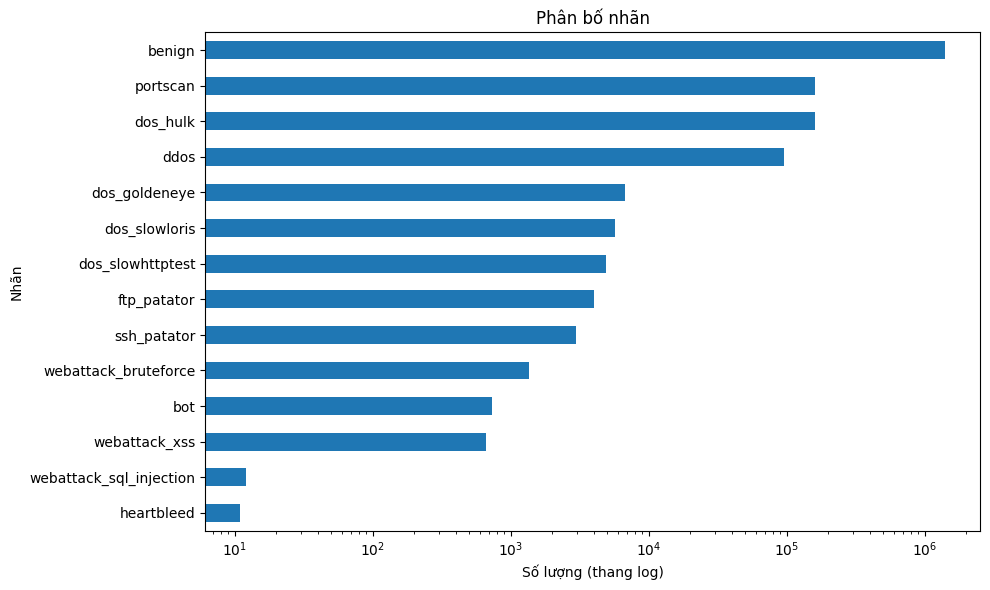

In [19]:
# Kiểm tra phân bổ nhãn
ax = label_table.sort_values('count').plot.barh(
    x='label',
    y='count',
    figsize=(10, 6),
    legend=False
)

ax.set_xscale('log')
ax.set_title('Phân bố nhãn')
ax.set_xlabel('Số lượng (thang log)')
ax.set_ylabel('Nhãn')

plt.tight_layout()
plt.show()

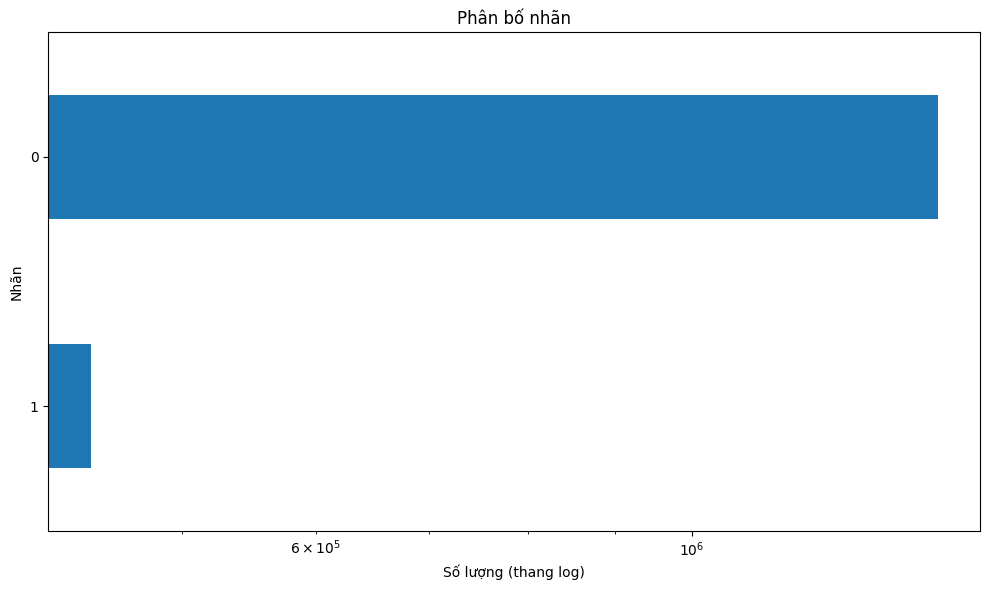

In [20]:
# Kiểm tra phân bổ nhãn
ax = attack_table.sort_values('count').plot.barh(
    x='label',
    y='count',
    figsize=(10, 6),
    legend=False
)

ax.set_xscale('log')
ax.set_title('Phân bố nhãn')
ax.set_xlabel('Số lượng (thang log)')
ax.set_ylabel('Nhãn')

plt.tight_layout()
plt.show()

In [21]:
# Kiểm tra cân bằng lớp
print("Số lớp:", len(label_table))
print("Lớp nhiều nhất:", label_table.iloc[0]['label'], "-", label_table.iloc[0]['count'], "mẫu")
print("Lớp ít nhất:", label_table.iloc[-1]['label'], "-", label_table.iloc[-1]['count'], "mẫu")
print("Tỷ lệ lớp lớn nhất / nhỏ nhất:",
      round(label_table['count'].max() / label_table['count'].min(), 1))

Số lớp: 14
Lớp nhiều nhất: benign - 1395675 mẫu
Lớp ít nhất: heartbleed - 11 mẫu
Tỷ lệ lớp lớn nhất / nhỏ nhất: 126879.5


In [22]:
# Kiểm tra cân bằng lớp
print("Số lớp:", len(attack_table))
print("Lớp nhiều nhất:", attack_table.iloc[0]['label'], "-", attack_table.iloc[0]['count'], "mẫu")
print("Lớp ít nhất:", attack_table.iloc[-1]['label'], "-", attack_table.iloc[-1]['count'], "mẫu")
print("Tỷ lệ lớp lớn nhất / nhỏ nhất:",
      round(attack_table['count'].max() / attack_table['count'].min(), 1))

Số lớp: 2
Lớp nhiều nhất: 0.0 - 1395675.0 mẫu
Lớp ít nhất: 1.0 - 441823.0 mẫu
Tỷ lệ lớp lớn nhất / nhỏ nhất: 3.2


## Features - numeric

In [23]:
# Thống kê mô tả
df_raw.describe(include='number')

,src_port,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,is_attack
count,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1837498.0,1837498.0,1837498.0,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06
mean,4.851412e+04,1.016174e+03,1.131388e+01,1.499277e+15,1.199375e+07,1.051375e+00,1.388679e+03,2.117446e+01,3.051886e+02,9.484971e+05,4.775796e+02,5.902847e+05,1.233599e+04,7.515683e+03,4.820309e+03,1.214130e+01,5.751877e+02,2.156581e+02,2.143513e+01,6.066870e+01,7.115022e+01,2.770368e+02,1.793393e+01,2.751816e+00,1.467427e+01,2.396352e+04,1.351654e+03,1.550679e-01,4.759030e+02,5.322375e+02,3.280494e+02,1.684333e+01,1.268193e+01,4.592725e+06,1.820236e+04,8.792799e+05,1.721531e+06,1.163050e+07,4.417167e+06,1.214749e+06,2.005897e+06,1.244304e+06,1.091002e+07,3.891474e+06,1.353950e+06,2.072981e+06,9.999340e+05,1.827067e+05,6.236271e+04,9.085547e+04,5.248137e+04,4.033050e+06,3.658133e+06,3.855138e+06,2.046651e+05,9.387292e-01,3.834197e-01,9.971603e-02,2.442314e+01,3.168392e+00,1.415754e+00,1.752638e+00,0.0,0.0,0.0,4.087079e-04,6.057149e-04,6.775367e+01,2.369940e-01,1.821951e+05,4.215857e+03,2.093305e+00,2.855677e+06,2.681484e+02,6.813951e+00,1.395996e+04,8.270970e+00,1.069511e+04,1.146236e+04,2.404482e-01
std,1.580724e+04,5.216598e+03,5.542912e+00,1.302638e+11,3.091508e+07,4.082071e-01,2.375817e+03,2.643862e+01,4.622562e+02,2.627050e+06,8.487727e+02,8.554230e+06,6.437455e+04,5.069289e+04,2.674976e+04,9.299889e+02,5.453320e+03,4.787516e+02,3.567512e+01,9.875525e+01,1.549067e+02,1.943498e+04,1.079900e+01,6.477690e+00,1.237128e+03,2.807826e+06,2.364553e+03,6.027267e+00,7.377988e+02,1.044318e+03,2.477432e+04,9.914960e+00,1.236598e+03,1.427997e+07,2.505621e+05,3.445050e+06,6.219367e+06,3.078804e+07,1.426006e+07,9.487244e+06,9.758034e+06,4.235076e+06,3.004978e+07,1.377562e+07,9.815013e+06,1.020862e+07,4.199289e+06,1.104878e+06,6.403329e+05,7.130510e+05,4.322259e+05,1.401476e+07,1.336863e+07,1.356828e+07,2.171198e+06,1.059359e+00,4.862193e-01,2.996211e-01,2.166668e+03,2.880648e+01,4.787257e+00,2.694965e+01,0.0,0.0,0.0,2.888114e-02,3.414

In [24]:
# Kiểm tra lệnh
df_num = df_raw.select_dtypes(include='number')

pd.DataFrame({
    'Skew gốc': df_num.skew(),
    'Skew log': np.log1p(df_num).skew()
}).round(4)

,Skew gốc,Skew log
src_port,-1.5805,-4.5697
dst_port,8.5333,1.9178
ip_prot,0.4125,0.0639
timestamp,0.0784,0.0783
flow_duration,2.6760,-0.0658
...,...,...
bwd_subflow_bytes_mean,253.3431,-0.4246
bwd_subflow_pkt_mean,258.9417,1.9901
fwd_tcp_init_win_bytes,1.6645,NaN
bwd_tcp_init_win_bytes,1.0011,NaN


In [25]:
# # Vẽ histogram trên thang thường và thang log(1+x)
# for col in numeric_cols:
#     data = df_raw[col].replace([np.inf, -np.inf], np.nan).dropna()
#     data_log = data[data >= 0]

#     fig, axes = plt.subplots(1, 2, figsize=(14, 4))

#     axes[0].hist(data, bins=50, color='steelblue', edgecolor='white')
#     axes[0].set_title(f'{col} - Thang thường')
#     axes[0].set_xlabel(col)
#     axes[0].set_ylabel('Số quan sát')

#     axes[1].hist(np.log1p(data_log), bins=50, color='orange', edgecolor='white')
#     axes[1].set_title(f'{col} - Thang log(1+x)')
#     axes[1].set_xlabel(f'log(1 + {col})')
#     axes[1].set_ylabel('Số quan sát')

#     plt.tight_layout()
#     plt.show()

In [26]:
# # Phân tích chi tiết từng biến numeric
# _analyzer = Analyzer()
# for col in numeric_cols:
#     _analyzer.analyze_numeric_variable(variable_name=col, df=df_raw)
#     print('=' * 50)

## Features - categorical

In [27]:
# Thực hiện thống kê mô tả - dữ liệu categorical
df_raw.select_dtypes(include=['object', 'string']).describe()

,flow_id,src_addr,dst_addr,label,source_day
count,1837498,1837498,1837498,1837498,1837498
unique,942759,268,18095,14,5
top,192.168.10.3-192.168.10.255-137-137-17,172.16.0.1,192.168.10.3,benign,Friday
freq,451,442471,602976,1395675,542962


In [28]:
# # Tần suất các biến phân loại có ý nghĩa; bỏ qua mã định danh duy nhất
# for col in category_cols:
#     counts = df_raw[col].value_counts(dropna=False)

#     if counts.size > 20:
#         fig, axes = plt.subplots(1, 2, figsize=(20, 6))
#         top_high = counts.nlargest(10).sort_values()
#         top_low = counts.nsmallest(10).sort_values(ascending=False)

#         axes[0].barh(top_high.index.astype(str), top_high.values, color='steelblue')
#         axes[0].bar_label(axes[0].containers[0], padding=3)
#         axes[0].set_title(f'{col} - Top 10 cao nhất')

#         axes[1].barh(top_low.index.astype(str), top_low.values, color='orange')
#         axes[1].bar_label(axes[1].containers[0], padding=3)
#         axes[1].set_title(f'{col} - Top 10 thấp nhất')
#     else:
#         fig, ax = plt.subplots(figsize=(12, 5))
#         counts = counts.sort_values()
#         ax.barh(counts.index.astype(str), counts.values, color='steelblue')
#         ax.bar_label(ax.containers[0], padding=3)
#         ax.set_title(f'Tần suất - {col}')
#         axes = [ax]

#     for ax in axes:
#         ax.set_xlabel('Số quan sát')
#         ax.spines[['top', 'right']].set_visible(False)
#         ax.margins(x=0.15)
#     plt.tight_layout()
#     plt.show()

## Correlation of 1 feature & target

In [29]:
def analyze_category_vs_continous(category_var,continous_var, df):
    lst = []
    for name, g in df.groupby(category_var):
        lst.append(g[continous_var])
    f_statistic, p_value = f_oneway(*lst)
    return f_statistic, p_value

### Target & numeric feature

In [30]:
# # target = ['label']
# target = ['is_attack']


# n = len(numeric_cols)
# m = len(target)

# for j in range(m):
#     indepen = []
#     dep = []
#     for i in range(n):

#         f_statistic, p_value = analyze_category_vs_continous(target[j],numeric_cols[i],df_raw)
#         alpha = 0.05
#         if p_value < alpha:
#             dep.append(numeric_cols[i])
#         else:
#             indepen.append(numeric_cols[i])
#     print()
#     print(f'Các biến có tác động đến {target}: {dep}')
#     print(f'Các biến không có tác động đến {target}: {indepen}')


### Target & categorical feature

In [31]:
# target_col = target[0]

# for col in category_cols:
#     if col == target_col:
#         continue

#     print('* ' * 40)
#     _analyzer.analyze_category_vs_category(
#         var1=target_col,
#         var2=col,
#         df=df_raw
#     )

## Correlation of 2 features

In [32]:
def analyze_continous_vs_continous(var_1, var_2, df):
    # Calculate Pearson correlation coefficient
    correlation_coefficient, p_value = stats.pearsonr(df[var_1], df[var_2])
    print('var 1=',var_1,',','var 2=',var_2)
    print(f"Pearson Correlation Coefficient: {correlation_coefficient:.2f} - P-value: {p_value:.4f}")
    sns.scatterplot(data=df, x=var_1, y=var_2)
    plt.show()

### Numeric & numeric

In [33]:
# n = len(numeric_cols)
# for i in range(n):
#     for j in range(i + 1, n):
#         print('* ' * 40)
#         analyze_continous_vs_continous(var_1=numeric_cols[i], var_2=numeric_cols[j], df=df_raw)

### Numeric & Categorical

In [34]:
# n = len(numeric_cols)
# m = len(category_cols)

# for j in range(m):
#     indepen = []
#     dep = []
#     for i in range(n):

#         f_statistic, p_value = analyze_category_vs_continous(category_cols[j],numeric_cols[i],df_raw)
#         alpha = 0.05
#         if p_value < alpha:
#             dep.append(numeric_cols[i])
#         else:
#             indepen.append(numeric_cols[i])
#     print()
#     print(f'Các biến có tác động đến {category_cols[j]}: {dep}')
#     print(f'Các biến không có tác động đến {category_cols[j]}: {indepen}')


### Categorical & Categorical

In [35]:
# n = len(category_cols)
# for i in range(n):
#     for j in range(i + 1, n):
#         print('* ' * 40)
#         _analyzer.analyze_category_vs_category(
#             var1=category_cols[i],
#             var2=category_cols[j],
#             df=df_raw
#         )

In [36]:
import pandas as pd
import numpy as np

df = df_raw.copy()

# Thay bằng tên cột mục tiêu thực tế
target = "target"

# Thống kê dữ liệu ban đầu
stats_before = {
    "Số dòng dữ liệu": len(df),
    "Số thuộc tính": df.shape[1] - 1,
    "Số giá trị thiếu": df.isna().sum().sum(),
    "Số dòng trùng lặp": df.duplicated().sum()
}

pd.DataFrame(
    stats_before.items(),
    columns=["Chỉ tiêu", "Trước xử lý"]
)

,Chỉ tiêu,Trước xử lý
0,Số dòng dữ liệu,1837498
1,Số thuộc tính,84
2,Số giá trị thiếu,0
3,Số dòng trùng lặp,0


In [37]:
quality = pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes.astype(str),
    "Số giá trị thiếu": df.isna().sum(),
    "Tỷ lệ thiếu (%)": df.isna().mean() * 100,
    "Số giá trị phân biệt": df.nunique()
})

display(
    quality.sort_values(
        "Tỷ lệ thiếu (%)",
        ascending=False
    )
)

,Kiểu dữ liệu,Số giá trị thiếu,Tỷ lệ thiếu (%),Số giá trị phân biệt
flow_id,object,0,0.0,942759
idle_max,float64,0,0.0,206246
flag_psh,int64,0,0.0,607
flag_ack,int64,0,0.0,2152
flag_rst,int64,0,0.0,2
...,...,...,...,...
bwd_pkt_cnt,int64,0,0.0,1644
fwd_non_empty_pkt_cnt,int64,0,0.0,309
fwd_pkt_hdr_len_min,int64,0,0.0,9
fwd_pkt_hdr_len_tot,int64,0,0.0,3435


# Preprocess

In [45]:
clean_log = []
issue_log = []

### Loại trùng & thiếu

In [46]:
df_clean = df.copy()

# 1. Xóa bản ghi trùng hoàn toàn
duplicate_mask = df_clean.duplicated()
n_duplicate = int(duplicate_mask.sum())
df_clean = df_clean.loc[~duplicate_mask].copy()
clean_log.append(["Trùng toàn bộ", n_duplicate, n_duplicate])

print("Trước xử lý:", len(df))
print("Sau xử lý:", len(df_clean))
print("Đã loại bỏ:", n_duplicate)

Trước xử lý: 1837498
Sau xử lý: 1837498
Đã loại bỏ: 0


## Đổi kiểu dữ liệu

In [47]:
# Đổi sang dữ liệu chuỗi
# ip_prot là mã giao thức, nên xem là biến phân loại.
text_cols = ["flow_id", "src_addr", "dst_addr", "source_day", 'ip_prot']

n_text_format = 0

for col in text_cols:
    before = df_clean[col].astype("string")
    after = before.str.strip().replace("", pd.NA)
    n_text_format += int((before.fillna("") != after.fillna("")).sum())
    df_clean[col] = after

clean_log.append(["Chuẩn hóa văn bản", 0, n_text_format])
print("Số giá trị văn bản không hợp lệ:", n_text_format)

# Chuyển các cột số về đúng kiểu; giá trị không chuyển được thành NaN
n_wrong_format = 0

for col in numeric_cols:
    before = df_clean[col]
    after = pd.to_numeric(before, errors="coerce")
    n_bad = int((before.notna() & after.isna()).sum())
    n_wrong_format += n_bad

    if n_bad > 0:
        issue_log.append([col, "Sai định dạng số", n_bad])

    df_clean[col] = after

clean_log.append(["Sai định dạng số", 0, n_wrong_format])
print("Số giá trị số không hợp lệ:", n_wrong_format)


Số giá trị văn bản không hợp lệ: 0
Số giá trị số không hợp lệ: 0


## Đánh dấu giá trị ngoài miền hợp lệ

In [ ]:
# Đánh dấu các giá trị ngoài miền hợp lệ
n_invalid_value = 0
for col in ["src_port", "dst_port"]:
    bad = (
        df_clean[col].notna()
        & (
            ~df_clean[col].between(0, 65535)
            | df_clean[col].mod(1).ne(0)
        )
    )
    n_bad = int(bad.sum())
    df_clean.loc[bad, col] = None
    n_invalid_value += n_bad

    if n_bad > 0:
        issue_log.append([col, "Cổng ngoài 0–65535 hoặc không nguyên", n_bad])
print("Số giá trị cổng không hợp lệ:", n_invalid_value)

bad = (
    df_clean["ip_prot"].notna()
    & (
        ~df_clean["ip_prot"].between(0, 255)
        | df_clean["ip_prot"].mod(1).ne(0)
    )
)
n_bad = int(bad.sum())
df_clean.loc[bad, "ip_prot"] = None
n_invalid_value += n_bad

if n_bad > 0:
    issue_log.append(["ip_prot", "Mã giao thức không hợp lệ", n_bad])
print("Số giá trị ip_prot không hợp lệ:", n_invalid_value)

# Các đại lượng đo dưới đây không thể âm.
# Riêng -1 ở hai cột tcp_init_win_bytes là mã thiếu của bộ trích xuất.
nonnegative_cols = [
    col for col in numeric_cols
    if col not in [
        "src_port", "dst_port", "ip_prot", "timestamp",
        "fwd_tcp_init_win_bytes", "bwd_tcp_init_win_bytes"
    ]
]

for col in nonnegative_cols:
    bad = df_clean[col] < 0
    n_bad = int(bad.sum())
    df_clean.loc[bad, col] = None
    n_invalid_value += n_bad

    if n_bad > 0:
        issue_log.append([col, "Giá trị âm không hợp lệ", n_bad])

clean_log.append(["Giá trị bất hợp lý → None", 0, n_invalid_value])
print("Số giá trị bất hợp lý:", n_invalid_value)

# ip_prot là mã phân loại, không phải đại lượng liên tục
df_clean["ip_prot"] = df_clean["ip_prot"].astype("Int64").astype("string")

clean_table = pd.DataFrame(
    clean_log,
    columns=["Bước", "Số dòng loại", "Số giá trị xử lý"]
)
issue_table = pd.DataFrame(
    issue_log,
    columns=["Cột", "Vấn đề", "Số giá trị xử lý"]
)

Số giá trị cổng không hợp lệ: 0
Số giá trị ip_prot không hợp lệ: 0
Số giá trị bất hợp lý: 2270


In [49]:
clean_table

,Bước,Số dòng loại,Số giá trị xử lý
0,Trùng toàn bộ,0,0
1,Chuẩn hóa văn bản,0,0
2,Sai định dạng số,0,0
3,Giá trị bất hợp lý → NaN,0,2270


In [50]:
issue_table

,Cột,Vấn đề,Số giá trị xử lý
0,iat_min,Giá trị âm không hợp lệ,2270


## Phân hạng features

In [44]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split

# Điền các cột định danh cần loại, nếu có
id_cols = ["flow_id", "src_addr", "dst_addr", "timestamp", "label"]
# cột id là duy nhất nên loại, label loại vì nó chứa nhãn
# loại "src_addr", "dst_addr" vì lỡ mô hình nhớ IP thì khó tổng quát khi gặp mạng mới
# timestamp không dùng trực tiếp vì trực tiếp dễ học lịch thu thập hoặc thời điểm diễn ra tấn công.
# ip_prot là mã giao thức, nên xem là biến phân loại.

print("Các cột loại thủ công:", id_cols)


target_col = 'is_attack'

# Loại thuộc tính thiếu >= 50% (ngưỡng minh họa)
feature_cols = df_clean.columns.drop(target_col)
missing_rate = df_clean[feature_cols].isna().mean()
drop_missing = missing_rate[missing_rate >= 0.5].index.tolist()
print("Các cột bị loại do thiếu >=50%:", drop_missing)

# Loại thuộc tính chỉ có 1 giá trị phân biệt hoặc ít hơn
drop_constant = [
    c for c in feature_cols
    if df_clean[c].nunique(dropna=True) <= 1
]
print("Các cột bị loại do thuộc tính chỉ có 1 giá trị:", drop_constant)


drop_cols = set(id_cols + drop_missing + drop_constant)

candidate_cols = [
    c for c in feature_cols if c not in drop_cols
]

X = df_clean[candidate_cols].copy()
y = df_clean[target_col]

# Chỉ dùng tập huấn luyện để lựa chọn thuộc tính
train_idx, test_idx = train_test_split(
    df_clean.index,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X.loc[train_idx].copy()
y_train = y.loc[train_idx]

numeric_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = [
    c for c in X_train.columns if c not in numeric_cols
]

# Xử lý thiếu tạm thời để tính MI
for col in numeric_cols:
    v = pd.to_numeric(
        X_train[col], errors="coerce"
    ).replace([np.inf, -np.inf], None)

    median = v.median()
    X_train[col] = v.fillna(
        median if pd.notna(median) else 0
    )

for col in categorical_cols:
    v = X_train[col].astype("string").fillna("__MISSING__")
    X_train[col] = pd.factorize(v)[0]

# Tính Mutual Information
mi_scores = mutual_info_classif(
    X_train,
    y_train,
    discrete_features=[
        c in categorical_cols for c in candidate_cols
    ],
    random_state=42
)

ranking = pd.DataFrame({
    "Thuộc tính": candidate_cols,
    "MI Score": mi_scores
}).sort_values(
    "MI Score", ascending=False
).reset_index(drop=True)

ranking

Các cột loại thủ công: ['flow_id', 'src_addr', 'dst_addr', 'timestamp', 'label']
Các cột bị loại do thiếu >=50%: []
Các cột bị loại do thuộc tính chỉ có 1 giá trị: ['flag_urg', 'fwd_flag_urg', 'bwd_flag_urg']


,Thuộc tính,MI Score
0,bwd_pkt_len_mean,0.475434
1,pkt_len_mean,0.471115
2,bwd_subflow_bytes_mean,0.467700
3,bwd_pkt_len_tot,0.463398
4,pkt_len_max,0.452190
...,...,...
71,fwd_bulk_rate_mean,0.012191
72,fwd_bulk_pkt_mean,0.008237
73,flag_cwr,0.000801
74,flag_ece,0.000581


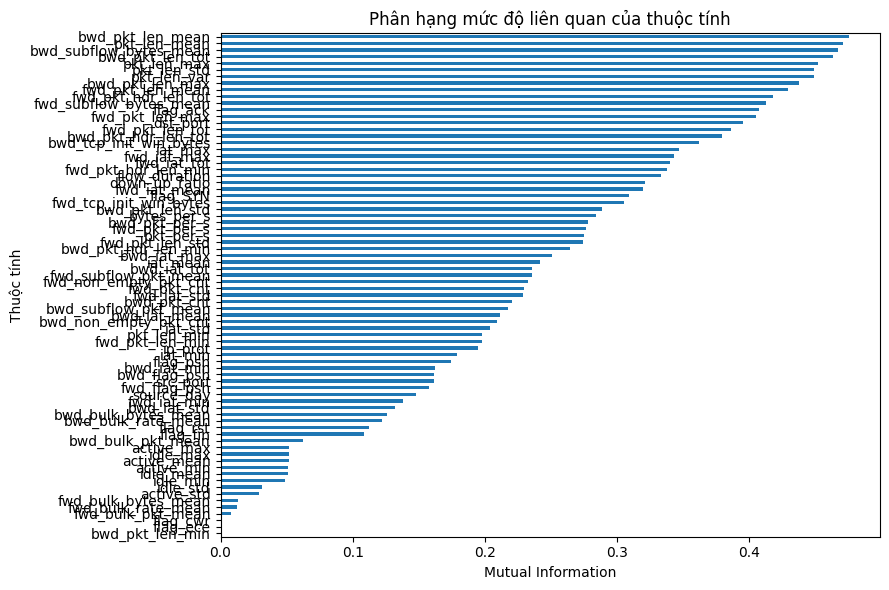

In [45]:
import matplotlib.pyplot as plt

ranking.sort_values("MI Score").plot.barh(
    x="Thuộc tính",
    y="MI Score",
    figsize=(9, 6),
    legend=False
)

plt.xlabel("Mutual Information")
plt.ylabel("Thuộc tính")
plt.title("Phân hạng mức độ liên quan của thuộc tính")
plt.tight_layout()
plt.show()

## Chọn thuộc tính

In [ ]:
# Ví dụ: chọn 10 thuộc tính đứng đầu
selected_features = ranking.head(10)["Thuộc tính"].tolist()

df_final = df_clean[selected_features + [target]].copy()

# Điền khuyết bằng thống kê từ tập huấn luyện
for col in selected_features:
    train_col = X.loc[train_idx, col]

    if col in numeric_cols:
        median = train_col.median()
        df_final[col] = df_final[col].fillna(
            median if pd.notna(median) else 0
        )
    else:
        mode = train_col.mode(dropna=True)
        fill_value = mode.iloc[0] if len(mode) else "Không rõ"
        df_final[col] = df_final[col].fillna(fill_value)

# Thống kê sau xử lý
stats_after = {
    "Số dòng dữ liệu": len(df_final),
    "Số thuộc tính": df_final.shape[1] - 1,
    "Số giá trị thiếu": int(df_final.isna().sum().sum()),
    "Số dòng trùng lặp": int(df_final.duplicated().sum())
}

comparison = pd.DataFrame({
    "Trước xử lý": stats_before,
    "Sau xử lý": stats_after
})

comparison["Chênh lệch"] = (
    comparison["Sau xử lý"] - comparison["Trước xử lý"]
)

comparison